# FairBatch on Adult, German and COMPAS
This notebook evaluates FairBatch (Roh et al., ICLR 2021) for demographic parity. Results are loaded from the results folder; delete a CSV there to rerun that experiment.

In [1]:
import pandas as pd
import seaborn as sns
from scipy.stats import wilcoxon

from fairness_eval import config as cfg, data, experiments as ex

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
HUE = ["test_labels", *ex.METHODS]

## 1. Datasets
z = 1 is the privileged group. base_rate is the share of favorable labels.

In [2]:
data.summary()

,dataset,rows,features,sensitive,share_privileged,base_rate,base_rate_z0,base_rate_z1
0,adult,45222,80,sex (male = 1),0.675,0.248,0.114,0.312
1,german,1000,48,age (older than 25 = 1),0.810,0.700,0.579,0.728
2,compas,5278,10,"race (Caucasian = 1, African-American = 0)",0.398,0.530,0.477,0.609


## 2. Fairness of the original labels
Measured on the full datasets, before any model is trained. DP_Diff is the favorable rate of the unprivileged group minus that of the privileged group, DIR is their ratio, and consistency measures how similar the labels of nearest neighbours are.

In [3]:
original = ex.original_fairness()
original

,dataset,dp_diff,dir,consistency
0,adult,-0.199,0.363,0.796
1,german,-0.149,0.795,0.658
2,compas,-0.132,0.783,0.619


## 3. Settings
Logistic regression trained with Adam on a stratified 70/30 split, 10 seeds. The baseline uses normal minibatches, fairbatch uses the authors' sampler, and fairbatch_rate is my own variant that updates the lambdas from the actual DP gap of the predictions.

In [4]:
pd.DataFrame(cfg.TRAIN).T

,batch_size,epochs,lr
adult,1000.0,600.0,0.005
german,50.0,300.0,0.005
compas,200.0,300.0,0.005


## 4. Choosing alpha
Alpha is chosen on a validation split of the training data, seeds 0 to 4. I take the alpha with the best balanced accuracy among those with |DP_Diff| at most 0.05, otherwise the one with the smallest |DP_Diff|.

,fairbatch,fairbatch_rate
adult,2.000e-02,2.000e-02
compas,5.000e-04,1.000e-02
german,2.500e-03,5.000e-04


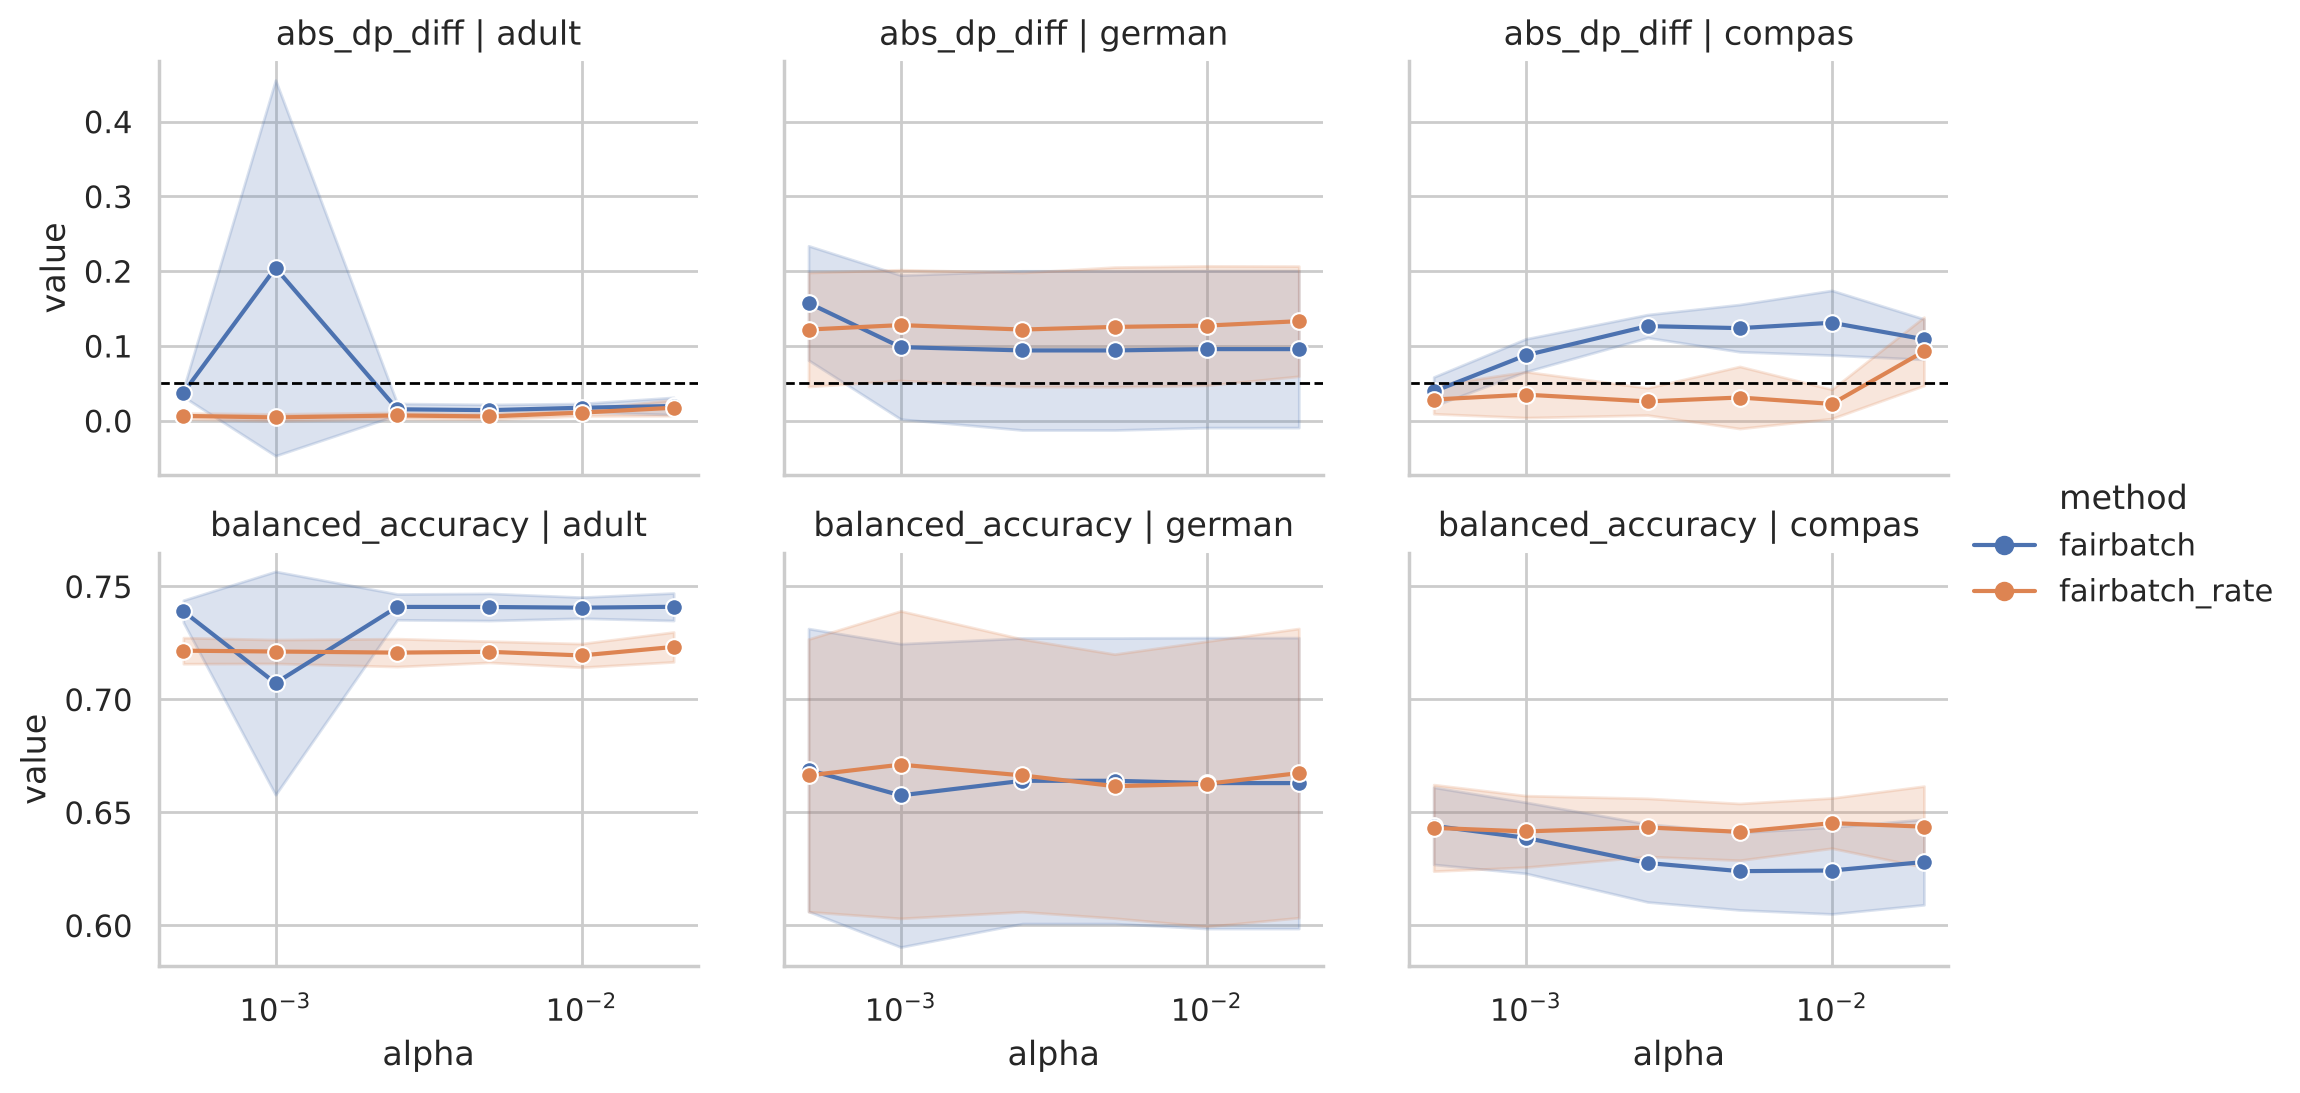

In [5]:
validation = ex.alpha_validation()
long = validation.assign(abs_dp_diff=validation.dp_diff.abs()).melt(["dataset", "method", "alpha"], ["abs_dp_diff", "balanced_accuracy"], "metric")
grid = sns.relplot(long, x="alpha", y="value", hue="method", col="dataset", row="metric", col_order=cfg.DATASETS,
                   kind="line", marker="o", errorbar="sd", height=2.8, aspect=1.2, facet_kws=dict(sharey="row"))
grid.set(xscale="log")
grid.set_titles(row_template="{row_name}", col_template="{col_name}")
for ax in grid.axes[0]:
    ax.axhline(cfg.DP_TOLERANCE, color="black", lw=1, ls="--")
chosen = ex.choose_alpha(validation)
pd.Series(chosen, name="alpha").unstack()

## 5. Before and after mitigation
Test set results, mean and standard deviation over 10 seeds. test_labels are the true labels of the test set, the other rows are predictions.

In [6]:
main = ex.main_experiment()
ex.summary(main)

dp_diff           dir        consistency         \
                          mean    std   mean    std        mean    std   
dataset method                                                           
adult   test_labels     -0.199  0.000  0.364  0.000       0.784  0.002   
        baseline        -0.190  0.007  0.287  0.012       0.931  0.002   
        fairbatch       -0.028  0.013  0.875  0.056       0.928  0.002   
        fairbatch_rate  -0.011  0.016  0.944  0.086       0.930  0.002   
german  test_labels     -0.149  0.000  0.795  0.000       0.642  0.015   
        baseline        -0.156  0.051  0.798  0.070       0.727  0.021   
        fairbatch       -0.043  0.055  0.944  0.071       0.738  0.028   
        fairbatch_rate  -0.037  0.056  0.951  0.072       0.734  0.021   
compas  test_labels     -0.132  0.000  0.783  0.000       0.610  0.009   
        baseline        -0.281  0.025  0.625  0.026       0.948  0.003   
        fairbatch        0.030  0.027  1.051  0.047       0.944  0.008   
        fairbatch_rate   0.012  0.059  1.024  0.105       0.946  0.007   

                       accuracy        balanced_accuracy         
                           mean    std              mean    std  
dataset method                                                   
adult   test_labels       1.000  0.000             1.000  0.000  
        baseline          0.845  0.002             0.764  0.006  
        fairbatch         0.828  0.003             0.745  0.005  
        fairbatch_rate    0.828  0.003             0.726  0.006  
german  test_labels       1.000  0.000             1.000  0.000  
        baseline          0.760  0.016             0.692  0.028  
        fairbatch         0.744  0.019             0.667  0.028  
        fairbatch_rate    0.754  0.021             0.679  0.029  
compas  test_labels       1.000  0.000             1.000  0.000  
        baseline          0.674  0.008             0.670  0.007  
        fairbatch         0.661  0.008             0.656  0.008  
        fairbatch_rate    0.661  0.009             0.656  0.009

In [7]:
# before: original labels on the full data; after: test set, mean over seeds
cols = ["dp_diff", "dir", "consistency"]
before = original.set_index("dataset")[cols]
before.columns = pd.MultiIndex.from_product([cols, ["original_labels"]])
after = main.groupby(["dataset", "method"])[cols].mean().unstack("method")
order = [(c, s) for c in cols for s in ["original_labels", *HUE]]
before.join(after)[order].loc[cfg.DATASETS]

dp_diff                                                \
        original_labels test_labels baseline fairbatch fairbatch_rate   
dataset                                                                 
adult            -0.199      -0.199   -0.190    -0.028         -0.011   
german           -0.149      -0.149   -0.156    -0.043         -0.037   
compas           -0.132      -0.132   -0.281     0.030          0.012   

                    dir                                                \
        original_labels test_labels baseline fairbatch fairbatch_rate   
dataset                                                                 
adult             0.363       0.364    0.287     0.875          0.944   
german            0.795       0.795    0.798     0.944          0.951   
compas            0.783       0.783    0.625     1.051          1.024   

            consistency                                                
        original_labels test_labels baseline fairbatch fairbatch_rate  
dataset                                                                
adult             0.796       0.784    0.931     0.928          0.930  
german            0.658       0.642    0.727     0.738          0.734  
compas            0.619       0.610    0.948     0.944          0.946

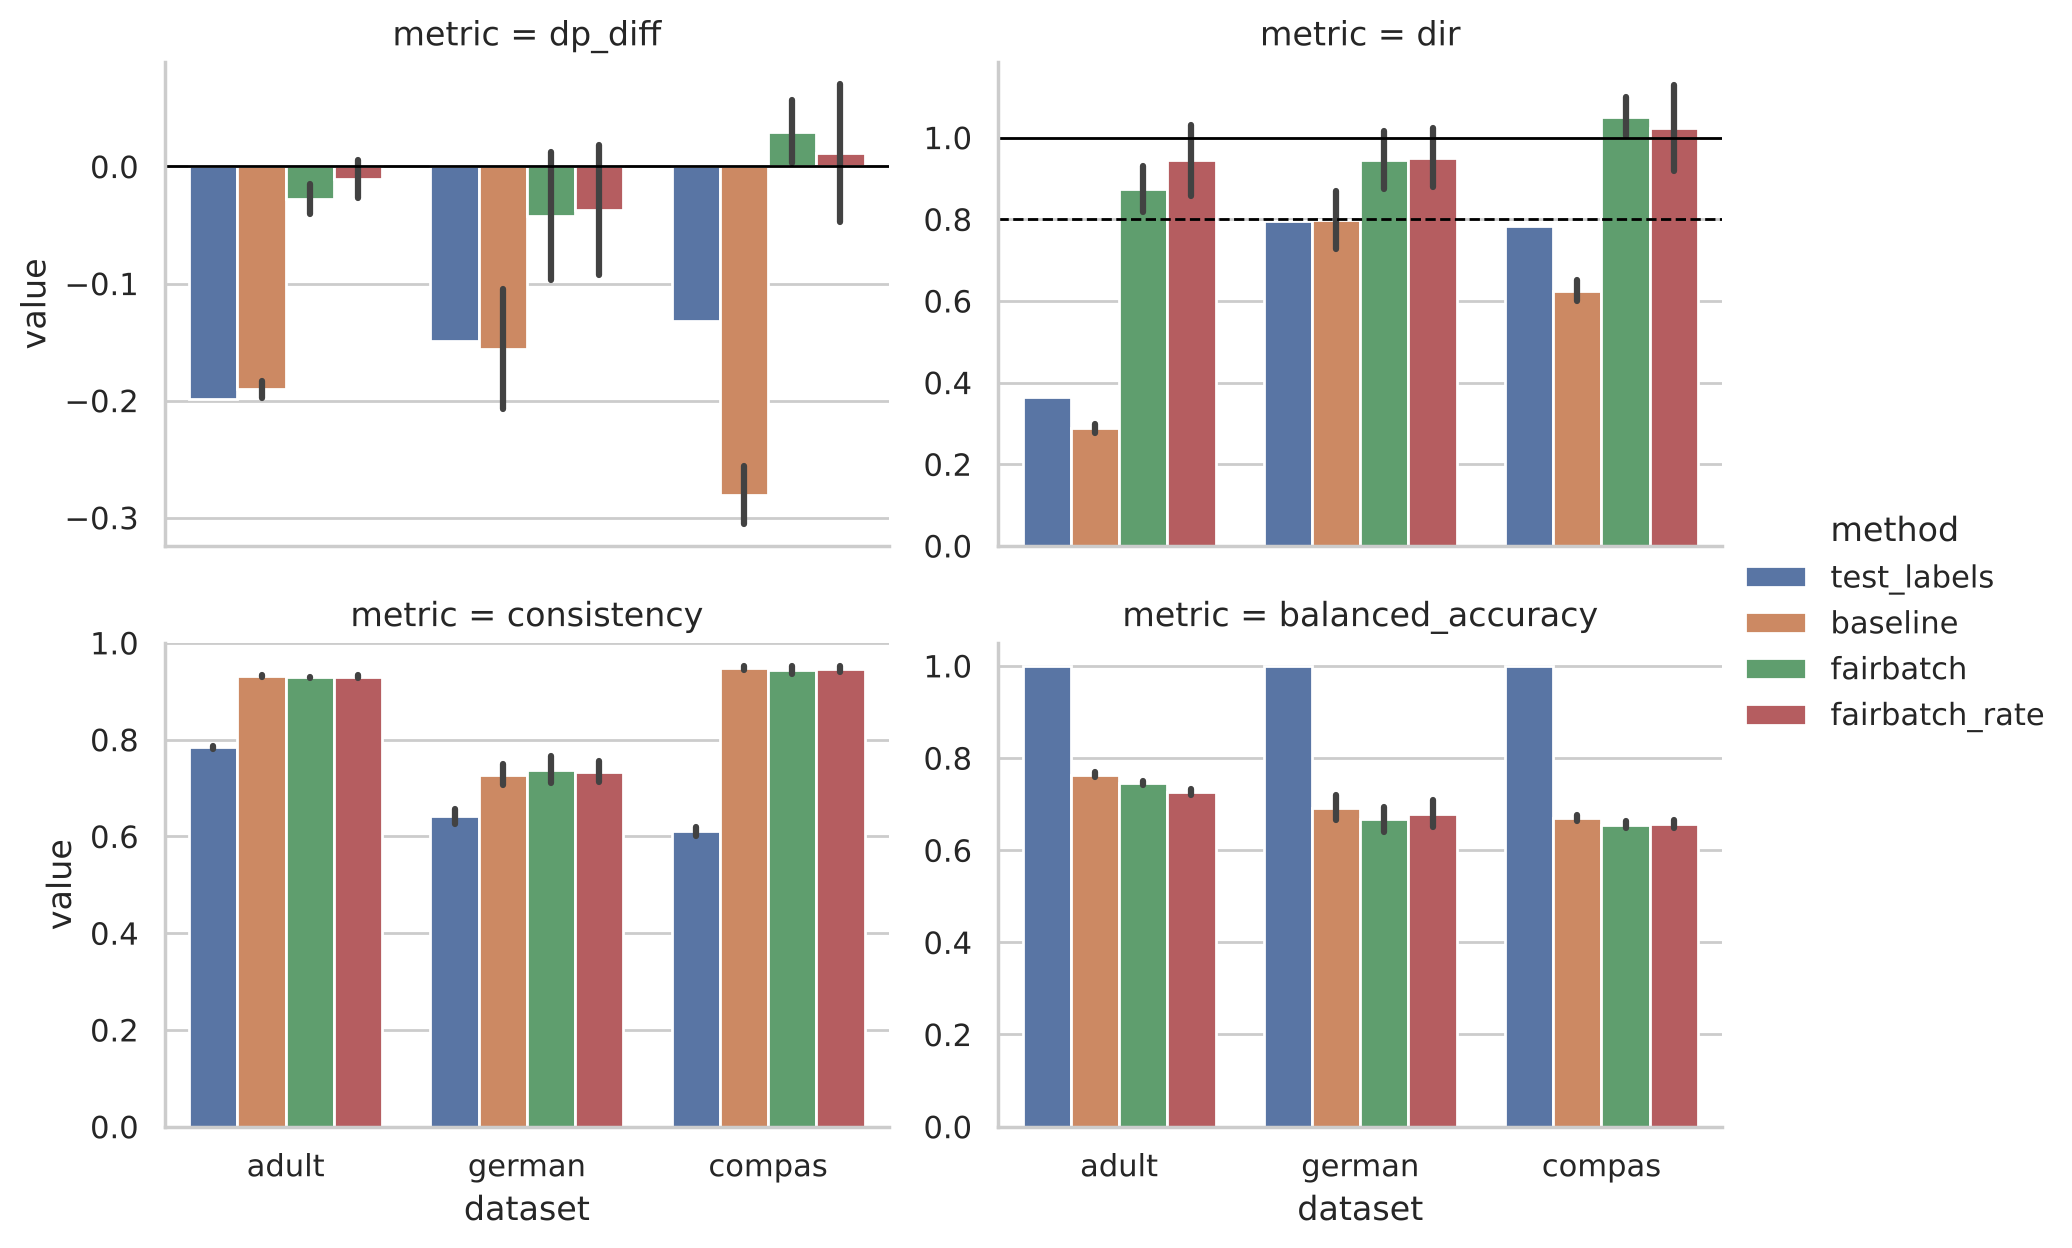

In [8]:
long = main.melt(["dataset", "method"], ["dp_diff", "dir", "consistency", "balanced_accuracy"], "metric")
grid = sns.catplot(long, x="dataset", y="value", hue="method", col="metric", col_wrap=2,
                   order=cfg.DATASETS, hue_order=HUE,
                   kind="bar", errorbar="sd", sharey=False, height=3.2, aspect=1.4)
grid.axes_dict["dp_diff"].axhline(0, color="black", lw=1)
grid.axes_dict["dir"].axhline(1, color="black", lw=1)
grid.axes_dict["dir"].axhline(0.8, color="black", lw=1, ls="--");  # four fifths rule

### Paired differences per seed
Each FairBatch variant minus the baseline on the same split, tested with Wilcoxon. With 10 seeds the smallest possible p value is 0.002.

In [9]:
rows = []
for metric in ["dp_diff", "dir", "consistency", "accuracy", "balanced_accuracy"]:
    wide = main.pivot_table(metric, ["dataset", "seed"], "method")
    for name in cfg.DATASETS:
        for method in ex.SAMPLERS:
            d = wide.loc[name, method] - wide.loc[name, "baseline"]
            rows.append({"dataset": name, "method": method, "metric": metric, "mean_diff": d.mean(),
                         "min": d.min(), "max": d.max(), "p_wilcoxon": wilcoxon(d).pvalue})
pd.DataFrame(rows).set_index(["dataset", "method", "metric"]).round(4)

mean_diff    min        max  \
dataset method         metric                                           
adult   fairbatch      dp_diff                0.162  0.145  1.923e-01   
        fairbatch_rate dp_diff                0.179  0.164  2.187e-01   
german  fairbatch      dp_diff                0.114  0.021  2.023e-01   
        fairbatch_rate dp_diff                0.119  0.034  2.385e-01   
compas  fairbatch      dp_diff                0.310  0.265  3.486e-01   
        fairbatch_rate dp_diff                0.292  0.227  3.823e-01   
adult   fairbatch      dir                    0.587  0.516  7.232e-01   
        fairbatch_rate dir                    0.656  0.572  8.751e-01   
german  fairbatch      dir                    0.146  0.021  2.701e-01   
        fairbatch_rate dir                    0.153  0.038  3.170e-01   
compas  fairbatch      dir                    0.426  0.369  4.723e-01   
        fairbatch_rate dir                    0.399  0.300  5.648e-01   
adult   fairbatch      consistency           -0.003 -0.006  3.000e-04   
        fairbatch_rate consistency           -0.001 -0.005  2.500e-03   
german  fairbatch      consistency            0.011 -0.012  3.070e-02   
        fairbatch_rate consistency            0.006 -0.015  2.530e-02   
compas  fairbatch      consistency           -0.004 -0.016  1.010e-02   
        fairbatch_rate consistency           -0.002 -0.014  8.200e-03   
adult   fairbatch      accuracy              -0.018 -0.023 -1.360e-02   
        fairbatch_rate accuracy              -0.017 -0.023 -1.210e-02   
german  fairbatch      accuracy              -0.017 -0.033  3.300e-03   
        fairbatch_rate accuracy              -0.007 -0.033  1.670e-02   
compas  fairbatch      accuracy              -0.013 -0.025 -1.300e-03   
        fairbatch_rate accuracy              -0.013 -0.026 -1.900e-03   
adult   fairbatch      balanced_accuracy     -0.018 -0.026 -9.700e-03   
        fairbatch_rate balanced_accuracy     -0.038 -0.043 -2.860e-02   
german  fairbatch      balanced_accuracy     -0.025 -0.046 -4.000e-03   
        fairbatch_rate balanced_accuracy     -0.013 -0.037  2.400e-03   
compas  fairbatch      balanced_accuracy     -0.014 -0.027 -1.400e-03   
        fairbatch_rate balanced_accuracy     -0.014 -0.028 -3.600e-03   

                                          p_wilcoxon  
dataset method         metric                         
adult   fairbatch      dp_diff                 0.002  
        fairbatch_rate dp_diff                 0.002  
german  fairbatch      dp_diff                 0.002  
        fairbatch_rate dp_diff                 0.002  
compas  fairbatch      dp_diff                 0.002  
        fairbatch_rate dp_diff                 0.002  
adult   fairbatch      dir                     0.002  
        fairbatch_rate dir                     0.002  
german  fairbatch      dir                     0.002  
        fairbatch_rate dir                     0.002  
compas  fairbatch      dir                     0.002  
        fairbatch_rate dir                     0.002  
adult   fairbatch      consistency             0.006  
        fairbatch_rate consistency             0.287  
german  fairbatch      consistency             0.084  
        fairbatch_rate consistency             0.160  
compas  fairbatch      consistency             0.098  
        fairbatch_rate consistency             0.426  
adult   fairbatch      accuracy                0.002  
        fairbatch_rate accuracy                0.002  
german  fairbatch      accuracy                0.016  
        fairbatch_rate accuracy                0.094  
compas  fairbatch      accuracy                0.002  
        fairbatch_rate accuracy                0.002  
adult   fairbatch      balanced_accuracy       0.002  
        fairbatch_rate balanced_accuracy       0.002  
german  fairbatch      balanced_accuracy       0.002  
        fairbatch_rate balanced_accuracy       0.004  
compas  fairbatch      balanced_accuracy       0.002  


## 6. Comparison with the paper
Table 2 of the paper reports accuracy and DP disparity on Adult with sex as the sensitive attribute, the one setting shared with the paper. The paper uses AIF360's preprocessing and a 4:1 split, I use the raw UCI files and a 7:3 split.

In [10]:
ours = main.query("dataset == 'adult' and method in ['baseline', 'fairbatch']").groupby("method")[["accuracy", "dp_paper"]].agg(["mean", "std"])
ours.columns = [f"ours_{m}_{a}" for m, a in ours.columns]
paper = pd.DataFrame(cfg.PAPER_TABLE2_ADULT, index=["paper_accuracy", "paper_dp"]).T
ours.join(paper)

,ours_accuracy_mean,ours_accuracy_std,ours_dp_paper_mean,ours_dp_paper_std,paper_accuracy,paper_dp
method,,,,,,
baseline,0.845,0.002,0.128,0.005,0.845,0.125
fairbatch,0.828,0.003,0.019,0.009,0.823,0.010


## 7. Lambda updates
Lambdas and the DP gap on the training data after every epoch, seed 0. lambda1 is the share of the privileged group among sampled positives, lambda2 the same for negatives. fairbatch moves one lambda per epoch based on the surrogate loss, fairbatch_rate moves both based on the actual gap.

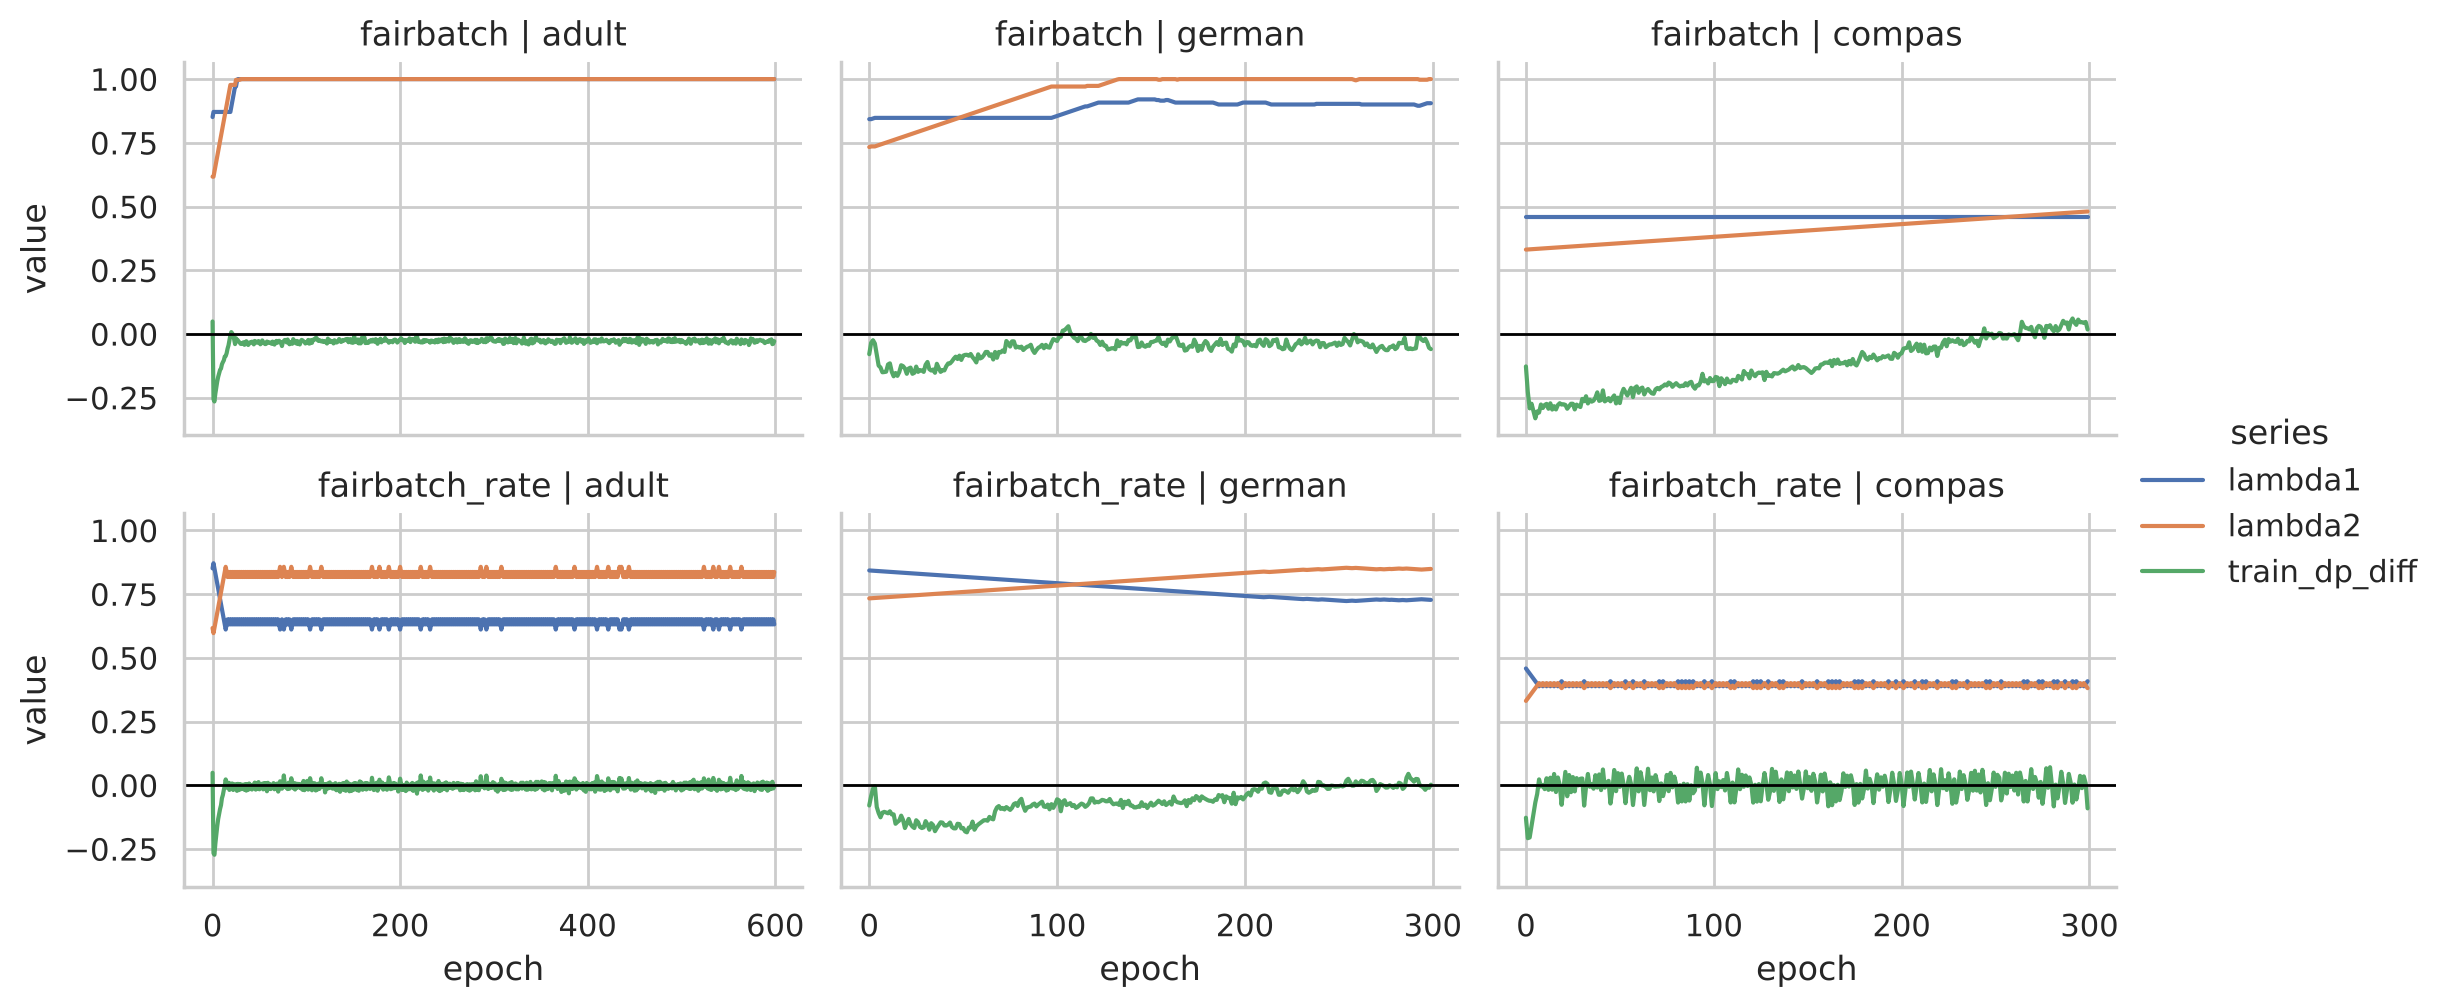

In [11]:
tr = ex.trace()
long = tr.melt(["dataset", "method", "epoch"], ["lambda1", "lambda2", "train_dp_diff"], "series")
grid = sns.relplot(long, x="epoch", y="value", hue="series", col="dataset", row="method", col_order=cfg.DATASETS,
                   kind="line", height=2.6, aspect=1.4, facet_kws=dict(sharex="col"))
grid.set_titles(row_template="{row_name}", col_template="{col_name}")
for ax in grid.axes.flat:
    ax.axhline(0, color="black", lw=1)

## 8. Conclusion
FairBatch reduced the demographic parity gap on all three datasets: from -0.19 to -0.03 on Adult, from -0.16 to -0.04 on German and from -0.28 to 0.03 on COMPAS, where it slightly overshot in favour of the unprivileged group. The cost was a drop in balanced accuracy of about 1.5 to 2.5 points, and consistency hardly changed. On COMPAS the baseline model doubled the gap already present in the labels, and FairBatch removed it. My rate based variant got slightly closer to parity but was not clearly better overall, since it lost more accuracy on Adult.